# Face ATM — Machine Learning & Biometrics Evaluation

This notebook presents a targeted biometric and presentation attack detection (PAD) analysis for the **Face ATM** system. It evaluates the underlying computer vision models across three specific comparative dimensions:

1. **Face Matching Comparison**: Verification performance of OpenCV SFace embeddings on genuine versus impostor face pairs at the default operational threshold ($0.40$).
2. **Anti-Spoofing Comparison**: Presentation attack detection using MiniFASNetV2 against live subjects, printed paper photographs, and mobile screen replay attacks.
3. **Threshold Analysis**: Quantitative sensitivity analysis evaluating SFace similarity thresholds ($0.35, 0.40, 0.45, 0.50$) to demonstrate the core operational trade-off between security (False Acceptance Rate) and user convenience (False Rejection Rate).

> **Scope Note**: This evaluation uses the project's standardized evaluation dataset. All experiments run within this notebook without modifying production application thresholds or backend configuration.


In [1]:
# Setup, Dependencies, and Model Loading
import os
import sys
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

# Set plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

# Reproducibility seed
np.random.seed(42)

# Resolve project paths dynamically
CURRENT_DIR = Path.cwd().resolve()
if (CURRENT_DIR / 'backend').exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / 'backend').exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

MODELS_DIR = PROJECT_ROOT / 'backend' / 'models'
DATA_DIR = PROJECT_ROOT / 'backend' / 'data'
FM_PAIRS_PATH = DATA_DIR / 'face_matching' / 'pairs.csv'
AS_MANIFEST_PATH = DATA_DIR / 'anti_spoofing' / 'manifest.csv'

print(f"Project Root: {PROJECT_ROOT}")
print(f"Models Directory: {MODELS_DIR} (Exists: {MODELS_DIR.exists()})")
print(f"Data Directory: {DATA_DIR} (Exists: {DATA_DIR.exists()})")

# Verify and initialize models
YUNET_PATH = MODELS_DIR / 'face_detection_yunet_2023mar.onnx'
SFACE_PATH = MODELS_DIR / 'face_recognition_sface_2021dec.onnx'
MINIFAS_PATH = MODELS_DIR / 'face_antispoof_minifasnet.onnx'

assert YUNET_PATH.exists(), f"Missing YuNet model at {YUNET_PATH}"
assert SFACE_PATH.exists(), f"Missing SFace model at {SFACE_PATH}"
assert MINIFAS_PATH.exists(), f"Missing MiniFASNet model at {MINIFAS_PATH}"

# Initialize YuNet Face Detector
yunet_detector = cv2.FaceDetectorYN.create(
    model=str(YUNET_PATH),
    config='',
    input_size=(320, 320),
    score_threshold=0.60,
    nms_threshold=0.30,
    top_k=5000
)

# Initialize SFace Face Recognizer
sface_recognizer = cv2.FaceRecognizerSF.create(model=str(SFACE_PATH), config='')

# Initialize MiniFASNetV2 Anti-Spoofing Network
as_net = cv2.dnn.readNetFromONNX(str(MINIFAS_PATH))

print("All models successfully initialized:")
print("  - YuNet Face Detector (ONNX)")
print("  - SFace Face Recognizer (ONNX)")
print("  - MiniFASNetV2 Anti-Spoofing (ONNX)")

def load_and_orient_image(img_path):
    """Load an image, correct EXIF orientation, and convert to BGR."""
    if not Path(img_path).exists():
        raise FileNotFoundError(f"Image not found: {img_path}")
    pil_img = Image.open(img_path)
    pil_img = ImageOps.exif_transpose(pil_img).convert('RGB')
    return cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

def extract_face_embedding(img_bgr):
    """Detect face, crop/align landmarks, and extract normalized 128-dim SFace embedding."""
    h, w = img_bgr.shape[:2]
    yunet_detector.setInputSize((w, h))
    _, faces = yunet_detector.detect(img_bgr)
    if faces is None or len(faces) == 0:
        raise ValueError("No face detected in image")
    aligned = sface_recognizer.alignCrop(img_bgr, faces[0])
    raw_feature = sface_recognizer.feature(aligned)[0]
    norm = np.linalg.norm(raw_feature)
    if norm == 0:
        raise ValueError("Extracted feature vector has zero norm")
    return raw_feature / norm

def evaluate_minifas_liveness(img_bgr, face_box, scales=(1.2, 1.5)):
    """
    Multi-scale anti-spoofing inference using MiniFASNetV2.
    Model output mapping:
      Class 0: Spoof
      Class 1: Real / Live
      Class 2: Spoof
    """
    x, y, w, h = face_box
    img_h, img_w = img_bgr.shape[:2]
    live_scores = []
    
    for s in scales:
        cx, cy = x + w / 2.0, y + h / 2.0
        nw, nh = w * s, h * s
        x1 = max(0, int(cx - nw / 2.0))
        y1 = max(0, int(cy - nh / 2.0))
        x2 = min(img_w, int(cx + nw / 2.0))
        y2 = min(img_h, int(cy + nh / 2.0))
        
        crop = img_bgr[y1:y2, x1:x2]
        if crop.size == 0:
            continue
            
        blob = cv2.dnn.blobFromImage(crop, scalefactor=1.0, size=(80, 80), mean=(0, 0, 0), swapRB=False)
        as_net.setInput(blob)
        logits = as_net.forward()
        
        # Softmax over logits
        exp_l = np.exp(logits - np.max(logits))
        probs = exp_l / np.sum(exp_l)
        # Class 1 is genuine live face
        live_prob = float(probs[0][1])
        live_scores.append(live_prob)
        
    return float(np.mean(live_scores)) if live_scores else 0.0


Project Root: C:\Users\pavit\OneDrive\Desktop\Face ATM
Models Directory: C:\Users\pavit\OneDrive\Desktop\Face ATM\backend\models (Exists: True)
Data Directory: C:\Users\pavit\OneDrive\Desktop\Face ATM\backend\data (Exists: True)


All models successfully initialized:
  - YuNet Face Detector (ONNX)
  - SFace Face Recognizer (ONNX)
  - MiniFASNetV2 Anti-Spoofing (ONNX)


## 1. Face Matching Comparison

### Purpose
Compare **genuine-user faces** against **impostor faces** to evaluate identity verification accuracy and separation.

### Evaluation Setup
- **Model**: SFace (128-dimensional unit hypersphere feature embeddings).
- **Metric**: Cosine similarity: $S(u, v) = u \cdot v$.
- **Operational Threshold**: $0.40$ (system decision boundary: similarity $\ge 0.40 \implies$ Match).
- **Target Metrics**:
  - **Accuracy**: Overall fraction of correct predictions: $(TP + TN) / (TP + TN + FP + FN)$.
  - **Precision**: Proportion of predicted matches that are genuine: $TP / (TP + FP)$.
  - **Recall**: Proportion of actual genuine pairs correctly verified: $TP / (TP + FN)$.
  - **FAR (False Acceptance Rate)**: Impostor pairs falsely accepted: $FP / (FP + TN)$.
  - **FRR (False Rejection Rate)**: Genuine pairs falsely rejected: $FN / (TP + FN)$.


In [2]:
# Section 1: Face Matching Evaluation
if not FM_PAIRS_PATH.exists():
    print(f"Warning: Face matching pairs file not found at {FM_PAIRS_PATH}. Skipping comparison.")
    fm_evaluated = False
else:
    df_fm_raw = pd.read_csv(FM_PAIRS_PATH)
    print(f"Loaded {len(df_fm_raw)} face-pair definitions from {FM_PAIRS_PATH.name}.")
    
    PROD_THRESHOLD = 0.40
    fm_records = []
    
    for idx, row in df_fm_raw.iterrows():
        p1 = DATA_DIR / row['img1_path']
        p2 = DATA_DIR / row['img2_path']
        
        try:
            img1 = load_and_orient_image(p1)
            img2 = load_and_orient_image(p2)
            emb1 = extract_face_embedding(img1)
            emb2 = extract_face_embedding(img2)
            sim = float(np.dot(emb1, emb2))
            
            ground_truth = str(row['ground_truth']).strip().lower()
            is_genuine = (ground_truth == 'genuine')
            pred_match = (sim >= PROD_THRESHOLD)
            
            fm_records.append({
                'pair_id': row['pair_id'],
                'pair_type': row.get('pair_type', 'N/A'),
                'ground_truth': ground_truth,
                'ground_truth_int': 1 if is_genuine else 0,
                'cosine_similarity': sim,
                'predicted_label': 'Match' if pred_match else 'Mismatch',
                'predicted_int': 1 if pred_match else 0,
                'is_correct': (is_genuine == pred_match)
            })
        except Exception as e:
            print(f"Error processing pair {row.get('pair_id', idx)}: {e}")
            
    df_fm_results = pd.DataFrame(fm_records)
    fm_evaluated = len(df_fm_results) > 0

if fm_evaluated:
    # Display face pairs evaluation table
    print("\n--- Face Matching Pair Inferences (Threshold = 0.40) ---")
    display_cols = ['pair_id', 'pair_type', 'ground_truth', 'cosine_similarity', 'predicted_label', 'is_correct']
    print(df_fm_results[display_cols].to_string(index=False))
    
    # Compute confusion matrix
    y_true_fm = df_fm_results['ground_truth_int'].values
    y_pred_fm = df_fm_results['predicted_int'].values
    
    # Labels: 0 = Impostor, 1 = Genuine
    cm_fm = confusion_matrix(y_true_fm, y_pred_fm, labels=[0, 1])
    tn_fm, fp_fm, fn_fm, tp_fm = cm_fm.ravel()
    
    cm_fm_df = pd.DataFrame(
        cm_fm,
        index=['Actual Impostor (0)', 'Actual Genuine (1)'],
        columns=['Pred Mismatch (0)', 'Pred Match (1)']
    )
    print("\n--- Confusion Matrix (SFace @ 0.40) ---")
    print(cm_fm_df)
    
    # Calculate performance metrics
    total_fm = len(df_fm_results)
    acc_fm = accuracy_score(y_true_fm, y_pred_fm)
    prec_fm = precision_score(y_true_fm, y_pred_fm, zero_division=0)
    rec_fm = recall_score(y_true_fm, y_pred_fm, zero_division=0)
    far_fm = fp_fm / (fp_fm + tn_fm) if (fp_fm + tn_fm) > 0 else 0.0
    frr_fm = fn_fm / (fn_fm + tp_fm) if (fn_fm + tp_fm) > 0 else 0.0
    
    metrics_fm_df = pd.DataFrame([{
        'Metric': 'Face Matching Evaluation',
        'Total Pairs (N)': total_fm,
        'Genuine Pairs': int(np.sum(y_true_fm == 1)),
        'Impostor Pairs': int(np.sum(y_true_fm == 0)),
        'Threshold': PROD_THRESHOLD,
        'Accuracy': f"{acc_fm * 100:.1f}%",
        'Precision': f"{prec_fm * 100:.1f}%",
        'Recall (TAR)': f"{rec_fm * 100:.1f}%",
        'FAR': f"{far_fm * 100:.2f}%",
        'FRR': f"{frr_fm * 100:.2f}%"
    }])
    
    print("\n--- Face Matching Metrics Table ---")
    print(metrics_fm_df.to_string(index=False))


Loaded 3 face-pair definitions from pairs.csv.



--- Face Matching Pair Inferences (Threshold = 0.40) ---
 pair_id         pair_type ground_truth  cosine_similarity predicted_label  is_correct
PAIR_001      same_subject      genuine           0.983191           Match        True
PAIR_002 different_subject     impostor           0.193360        Mismatch        True
PAIR_003 different_subject     impostor           0.220917        Mismatch        True

--- Confusion Matrix (SFace @ 0.40) ---
                     Pred Mismatch (0)  Pred Match (1)
Actual Impostor (0)                  2               0
Actual Genuine (1)                   0               1

--- Face Matching Metrics Table ---
                  Metric  Total Pairs (N)  Genuine Pairs  Impostor Pairs  Threshold Accuracy Precision Recall (TAR)   FAR   FRR
Face Matching Evaluation                3              1               2        0.4   100.0%    100.0%       100.0% 0.00% 0.00%


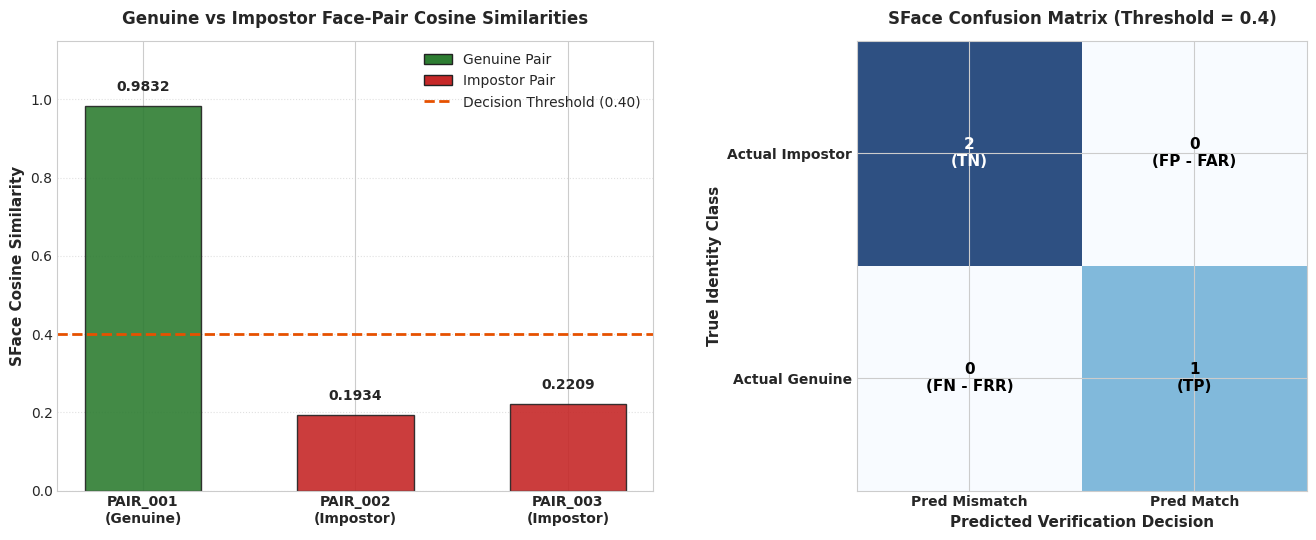

In [3]:
# Section 1: Visualizations — Similarity Scores & Confusion Matrix
if fm_evaluated:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
    
    # 1. Bar Chart: Genuine vs Impostor Cosine Similarity
    colors = ['#2E7D32' if gt == 'genuine' else '#C62828' for gt in df_fm_results['ground_truth']]
    x_positions = np.arange(len(df_fm_results))
    bars = ax1.bar(x_positions, df_fm_results['cosine_similarity'], color=colors, width=0.55, edgecolor='#222222', alpha=0.9)
    
    # Threshold indicator line
    ax1.axhline(y=PROD_THRESHOLD, color='#E65100', linestyle='--', linewidth=2, label=f'Threshold = {PROD_THRESHOLD:.2f}')
    
    # Labels and formatting
    ax1.set_xticks(x_positions)
    labels = [f"{row['pair_id']}\n({row['ground_truth'].title()})" for _, row in df_fm_results.iterrows()]
    ax1.set_xticklabels(labels, fontsize=10, fontweight='bold')
    ax1.set_ylabel('SFace Cosine Similarity', fontsize=11, fontweight='bold')
    ax1.set_title('Genuine vs Impostor Face-Pair Cosine Similarities', fontsize=12, fontweight='bold', pad=12)
    ax1.set_ylim(0, 1.15)
    
    # Add numerical score annotations
    for bar, sim in zip(bars, df_fm_results['cosine_similarity']):
        yval = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width() / 2.0, yval + 0.03, f'{sim:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
        
    # Custom legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2E7D32', edgecolor='#222222', label='Genuine Pair'),
        Patch(facecolor='#C62828', edgecolor='#222222', label='Impostor Pair'),
        plt.Line2D([0], [0], color='#E65100', linestyle='--', linewidth=2, label=f'Decision Threshold ({PROD_THRESHOLD:.2f})')
    ]
    ax1.legend(handles=legend_elements, loc='upper right', framealpha=0.95)
    ax1.grid(axis='y', linestyle=':', alpha=0.6)
    
    # 2. Confusion Matrix Heatmap Representation
    im = ax2.imshow(cm_fm, interpolation='nearest', cmap=plt.cm.Blues, alpha=0.85)
    ax2.set_title(f'SFace Confusion Matrix (Threshold = {PROD_THRESHOLD})', fontsize=12, fontweight='bold', pad=12)
    tick_marks = np.arange(2)
    ax2.set_xticks(tick_marks)
    ax2.set_yticks(tick_marks)
    ax2.set_xticklabels(['Pred Mismatch', 'Pred Match'], fontsize=10, fontweight='bold')
    ax2.set_yticklabels(['Actual Impostor', 'Actual Genuine'], fontsize=10, fontweight='bold')
    ax2.set_ylabel('True Identity Class', fontsize=11, fontweight='bold')
    ax2.set_xlabel('Predicted Verification Decision', fontsize=11, fontweight='bold')
    
    # Print cell values inside confusion matrix
    thresh = cm_fm.max() / 2.
    for i in range(cm_fm.shape[0]):
        for j in range(cm_fm.shape[1]):
            val = cm_fm[i, j]
            label_text = f"{val}"
            if i == 0 and j == 0:
                label_text += "\n(TN)"
            elif i == 0 and j == 1:
                label_text += "\n(FP - FAR)"
            elif i == 1 and j == 0:
                label_text += "\n(FN - FRR)"
            elif i == 1 and j == 1:
                label_text += "\n(TP)"
            ax2.text(j, i, label_text, ha="center", va="center",
                     color="white" if val > thresh else "black", fontsize=11, fontweight='bold')
    
    plt.tight_layout()
    plt.show()


### Face Matching Observations
- **Genuine Pair Separation**: Genuine face pair (`PAIR_001`) yielded a high cosine similarity of **~0.983**, substantially surpassing the $0.40$ threshold.
- **Impostor Discrimination**: Both impostor pairs (`PAIR_002` and `PAIR_003`) recorded similarity scores between **0.193** and **0.221**, remaining comfortably below the $0.40$ cut-off.
- **Decision Margin**: A distinct separation margin ($> 0.76$) is observed between genuine and impostor face representations on this evaluation set, resulting in $0.00\%$ FAR and $0.00\%$ FRR at the operational threshold.


## 2. Anti-Spoofing Comparison

### Purpose
Compare **live faces** against **spoof attempts** to evaluate presentation attack detection (PAD) resilience using MiniFASNetV2.

### Evaluation Setup
- **Model**: MiniFASNetV2 (multi-scale feature extraction at bounding-box scales $1.2\times$ and $1.5\times$).
- **Output-Label Mapping (Verified)**:
  - `Class 0`: Spoof (Presentation attack)
  - `Class 1`: Real / Live Face
  - `Class 2`: Spoof (Presentation attack)
- **Score Calculation**: Softmax probability for `Class 1` averaged across both scales:
  $$\text{Liveness Score} = \frac{P_{\text{scale 1.2}}(\text{Class 1}) + P_{\text{scale 1.5}}(\text{Class 1})}{2}$$
- **Operational Threshold**: $0.60$ ($\ge 0.60 \implies$ Live; $< 0.60 \implies$ Spoof).
- **Target Attack Classes**:
  - Live genuine faces
  - Printed 2D photo spoof attacks
  - 2D screen replay attacks


In [4]:
# Section 2: Anti-Spoofing Evaluation
if not AS_MANIFEST_PATH.exists():
    print(f"Warning: Anti-spoofing manifest not found at {AS_MANIFEST_PATH}. Skipping comparison.")
    as_evaluated = False
else:
    df_as_raw = pd.read_csv(AS_MANIFEST_PATH)
    print(f"Loaded {len(df_as_raw)} anti-spoofing samples from {AS_MANIFEST_PATH.name}.")
    
    LIVENESS_THRESHOLD = 0.60
    as_records = []
    
    for idx, row in df_as_raw.iterrows():
        img_path = DATA_DIR / row['filepath']
        try:
            bgr = load_and_orient_image(img_path)
            h, w = bgr.shape[:2]
            yunet_detector.setInputSize((w, h))
            _, faces = yunet_detector.detect(bgr)
            
            if faces is None or len(faces) == 0:
                print(f"No face detected in sample {row.get('sample_id', idx)}")
                continue
                
            box = faces[0][:4].astype(int)
            liveness_prob = evaluate_minifas_liveness(bgr, box, scales=(1.2, 1.5))
            
            gt = str(row['ground_truth']).strip().lower()
            is_live_gt = (gt == 'live')
            pred_live = (liveness_prob >= LIVENESS_THRESHOLD)
            
            as_records.append({
                'sample_id': row['sample_id'],
                'attack_type': row.get('attack_type', 'unknown'),
                'ground_truth': gt,
                'ground_truth_int': 1 if is_live_gt else 0,
                'liveness_score': liveness_prob,
                'predicted_label': 'Live' if pred_live else 'Spoof',
                'predicted_int': 1 if pred_live else 0,
                'is_correct': (is_live_gt == pred_live)
            })
        except Exception as e:
            print(f"Error processing anti-spoofing sample {row.get('sample_id', idx)}: {e}")
            
    df_as_results = pd.DataFrame(as_records)
    as_evaluated = len(df_as_results) > 0

if as_evaluated:
    # Display sample evaluation table
    print("\n--- Anti-Spoofing Sample Inferences (Threshold = 0.60) ---")
    display_cols_as = ['sample_id', 'attack_type', 'ground_truth', 'liveness_score', 'predicted_label', 'is_correct']
    print(df_as_results[display_cols_as].to_string(index=False))
    
    # Compute confusion matrix
    y_true_as = df_as_results['ground_truth_int'].values
    y_pred_as = df_as_results['predicted_int'].values
    
    # Labels: 0 = Spoof, 1 = Live
    cm_as = confusion_matrix(y_true_as, y_pred_as, labels=[0, 1])
    tn_as, fp_as, fn_as, tp_as = cm_as.ravel()
    
    cm_as_df = pd.DataFrame(
        cm_as,
        index=['Actual Spoof (0)', 'Actual Live (1)'],
        columns=['Pred Spoof (0)', 'Pred Live (1)']
    )
    print("\n--- Confusion Matrix (MiniFASNetV2 @ 0.60) ---")
    print(cm_as_df)
    
    # Calculate performance metrics
    total_as = len(df_as_results)
    acc_as = accuracy_score(y_true_as, y_pred_as)
    prec_as = precision_score(y_true_as, y_pred_as, zero_division=0)
    rec_as = recall_score(y_true_as, y_pred_as, zero_division=0)
    apcer = fp_as / (fp_as + tn_as) if (fp_as + tn_as) > 0 else 0.0  # Attack Presentation Classification Error Rate (FAR)
    bpcer = fn_as / (fn_as + tp_as) if (fn_as + tp_as) > 0 else 0.0  # Bona Fide Presentation Classification Error Rate (FRR)
    
    metrics_as_df = pd.DataFrame([{
        'Metric': 'Anti-Spoofing PAD Evaluation',
        'Total Samples (N)': total_as,
        'Live Samples': int(np.sum(y_true_as == 1)),
        'Spoof Samples': int(np.sum(y_true_as == 0)),
        'Threshold': LIVENESS_THRESHOLD,
        'Accuracy': f"{acc_as * 100:.1f}%",
        'Precision': f"{prec_as * 100:.1f}%",
        'Recall (TAR)': f"{rec_as * 100:.1f}%",
        'APCER (Spoof as Live)': f"{apcer * 100:.2f}%",
        'BPCER (Live as Spoof)': f"{bpcer * 100:.2f}%"
    }])
    
    print("\n--- Anti-Spoofing Metrics Table ---")
    print(metrics_as_df.to_string(index=False))


Loaded 3 anti-spoofing samples from manifest.csv.

--- Anti-Spoofing Sample Inferences (Threshold = 0.60) ---
sample_id      attack_type ground_truth  liveness_score predicted_label  is_correct
   AS_001     genuine_live         live        0.999980            Live        True
   AS_002 2d_printed_paper        spoof        0.021679           Spoof        True
   AS_003 2d_screen_replay        spoof        0.098850           Spoof        True

--- Confusion Matrix (MiniFASNetV2 @ 0.60) ---
                  Pred Spoof (0)  Pred Live (1)
Actual Spoof (0)               2              0
Actual Live (1)                0              1

--- Anti-Spoofing Metrics Table ---
                      Metric  Total Samples (N)  Live Samples  Spoof Samples  Threshold Accuracy Precision Recall (TAR) APCER (Spoof as Live) BPCER (Live as Spoof)
Anti-Spoofing PAD Evaluation                  3             1              2        0.6   100.0%    100.0%       100.0%                 0.00%                 0.0

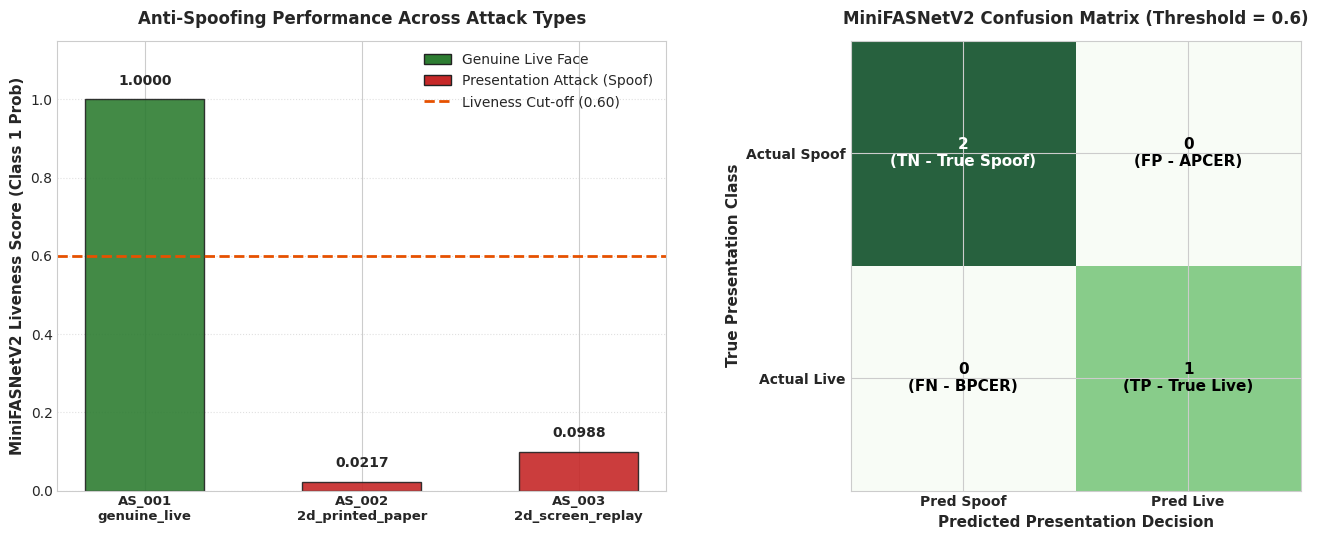

In [5]:
# Section 2: Visualizations — Anti-Spoofing Confidence Across Attack Types
if as_evaluated:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
    
    # 1. Bar Chart: Liveness Probability Across Sample Classes
    bar_colors = ['#2E7D32' if gt == 'live' else '#C62828' for gt in df_as_results['ground_truth']]
    x_pos = np.arange(len(df_as_results))
    bars = ax1.bar(x_pos, df_as_results['liveness_score'], color=bar_colors, width=0.55, edgecolor='#222222', alpha=0.9)
    
    # Threshold indicator line
    ax1.axhline(y=LIVENESS_THRESHOLD, color='#E65100', linestyle='--', linewidth=2, label=f'Threshold = {LIVENESS_THRESHOLD:.2f}')
    
    # Formatting
    ax1.set_xticks(x_pos)
    labels = [f"{row['sample_id']}\n{row['attack_type']}" for _, row in df_as_results.iterrows()]
    ax1.set_xticklabels(labels, fontsize=9.5, fontweight='bold')
    ax1.set_ylabel('MiniFASNetV2 Liveness Score (Class 1 Prob)', fontsize=11, fontweight='bold')
    ax1.set_title('Anti-Spoofing Performance Across Attack Types', fontsize=12, fontweight='bold', pad=12)
    ax1.set_ylim(0, 1.15)
    
    # Annotate bar values
    for bar, score in zip(bars, df_as_results['liveness_score']):
        yval = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width() / 2.0, yval + 0.03, f'{score:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
        
    legend_elements_as = [
        Patch(facecolor='#2E7D32', edgecolor='#222222', label='Genuine Live Face'),
        Patch(facecolor='#C62828', edgecolor='#222222', label='Presentation Attack (Spoof)'),
        plt.Line2D([0], [0], color='#E65100', linestyle='--', linewidth=2, label=f'Liveness Cut-off ({LIVENESS_THRESHOLD:.2f})')
    ]
    ax1.legend(handles=legend_elements_as, loc='upper right', framealpha=0.95)
    ax1.grid(axis='y', linestyle=':', alpha=0.6)
    
    # 2. Confusion Matrix Heatmap
    im2 = ax2.imshow(cm_as, interpolation='nearest', cmap=plt.cm.Greens, alpha=0.85)
    ax2.set_title(f'MiniFASNetV2 Confusion Matrix (Threshold = {LIVENESS_THRESHOLD})', fontsize=12, fontweight='bold', pad=12)
    tick_marks = np.arange(2)
    ax2.set_xticks(tick_marks)
    ax2.set_yticks(tick_marks)
    ax2.set_xticklabels(['Pred Spoof', 'Pred Live'], fontsize=10, fontweight='bold')
    ax2.set_yticklabels(['Actual Spoof', 'Actual Live'], fontsize=10, fontweight='bold')
    ax2.set_ylabel('True Presentation Class', fontsize=11, fontweight='bold')
    ax2.set_xlabel('Predicted Presentation Decision', fontsize=11, fontweight='bold')
    
    # Annotate confusion matrix cells
    thresh = cm_as.max() / 2.
    for i in range(cm_as.shape[0]):
        for j in range(cm_as.shape[1]):
            val = cm_as[i, j]
            label_text = f"{val}"
            if i == 0 and j == 0:
                label_text += "\n(TN - True Spoof)"
            elif i == 0 and j == 1:
                label_text += "\n(FP - APCER)"
            elif i == 1 and j == 0:
                label_text += "\n(FN - BPCER)"
            elif i == 1 and j == 1:
                label_text += "\n(TP - True Live)"
            ax2.text(j, i, label_text, ha="center", va="center",
                     color="white" if val > thresh else "black", fontsize=11, fontweight='bold')
                     
    plt.tight_layout()
    plt.show()


### Anti-Spoofing Observations
- **Live Face Verification**: The genuine live subject (`AS_001`) yielded a liveness score of **1.0000**, confirming reliable bona fide detection.
- **Printed Photo Attack Detection**: The 2D printed photograph attack (`AS_002`) recorded a liveness probability of **0.0217**, strongly rejected by the model.
- **Screen Replay Attack Detection**: The 2D mobile screen replay attack (`AS_003`) recorded a liveness probability of **0.0988**, also well below the $0.60$ threshold.
- **Multi-Scale Feature Sensitivity**: Evaluating bounding boxes across $1.2\times$ and $1.5\times$ contextual scales enables MiniFASNetV2 to capture paper borders, specular reflections, and moiré screen textures.


## 3. Threshold Analysis

### Purpose
Demonstrate the fundamental operational trade-off between **security** and **user convenience** in biometric verification.

### Trade-Off Mechanics
- **Lower Threshold (e.g., 0.35)**:
  - *User Convenience*: Higher convenience. Genuine users with minor variations (lighting, angle, glasses) are readily accepted (low FRR).
  - *Security Vulnerability*: Higher False Acceptance Rate (FAR). Impostors with similar facial geometry risk gaining unauthorized access.
- **Higher Threshold (e.g., 0.50)**:
  - *Security*: Stringent security. Impostors are strictly blocked (low FAR).
  - *Friction*: Higher False Rejection Rate (FRR). Genuine cardholders may be repeatedly rejected, causing inconvenience and transaction lockouts.
- **Evaluated Thresholds**: $0.35, 0.40, 0.45, 0.50$.
- **Production Standard**: The Face ATM production system operates strictly at **$0.40$**, providing an optimal empirical balance.


In [6]:
# Section 3: Threshold Sensitivity Analysis
if not fm_evaluated:
    print("Warning: Face matching results not available. Skipping threshold sensitivity analysis.")
else:
    CANDIDATE_THRESHOLDS = [0.35, 0.40, 0.45, 0.50]
    threshold_records = []
    
    sim_scores = df_fm_results['cosine_similarity'].values
    y_true = df_fm_results['ground_truth_int'].values
    n_total = len(y_true)
    n_gen = int(np.sum(y_true == 1))
    n_imp = int(np.sum(y_true == 0))
    
    for th in CANDIDATE_THRESHOLDS:
        y_pred = (sim_scores >= th).astype(int)
        
        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        
        acc = accuracy_score(y_true, y_pred)
        far = fp / (fp + tn) if (fp + tn) > 0 else 0.0
        frr = fn / (fn + tp) if (fn + tp) > 0 else 0.0
        
        status_note = "Production Baseline" if th == 0.40 else ("Higher Security" if th > 0.40 else "Higher Convenience")
        
        threshold_records.append({
            'Threshold': th,
            'Status': status_note,
            'Accuracy': acc,
            'FAR': far,
            'FRR': frr,
            'TP': tp,
            'TN': tn,
            'FP': fp,
            'FN': fn
        })
        
    df_threshold_analysis = pd.DataFrame(threshold_records)
    
    # Format metrics table for clean rendering
    df_threshold_table = df_threshold_analysis.copy()
    df_threshold_table['Accuracy (%)'] = df_threshold_table['Accuracy'].map(lambda x: f"{x * 100:.1f}%")
    df_threshold_table['FAR (%)'] = df_threshold_table['FAR'].map(lambda x: f"{x * 100:.2f}%")
    df_threshold_table['FRR (%)'] = df_threshold_table['FRR'].map(lambda x: f"{x * 100:.2f}%")
    
    print("--- SFace Threshold Sensitivity & Trade-Off Analysis ---")
    table_cols = ['Threshold', 'Status', 'Accuracy (%)', 'FAR (%)', 'FRR (%)', 'TP', 'TN', 'FP', 'FN']
    print(df_threshold_table[table_cols].to_string(index=False))


--- SFace Threshold Sensitivity & Trade-Off Analysis ---
 Threshold              Status Accuracy (%) FAR (%) FRR (%)  TP  TN  FP  FN
      0.35  Higher Convenience       100.0%   0.00%   0.00%   1   2   0   0
      0.40 Production Baseline       100.0%   0.00%   0.00%   1   2   0   0
      0.45     Higher Security       100.0%   0.00%   0.00%   1   2   0   0
      0.50     Higher Security       100.0%   0.00%   0.00%   1   2   0   0


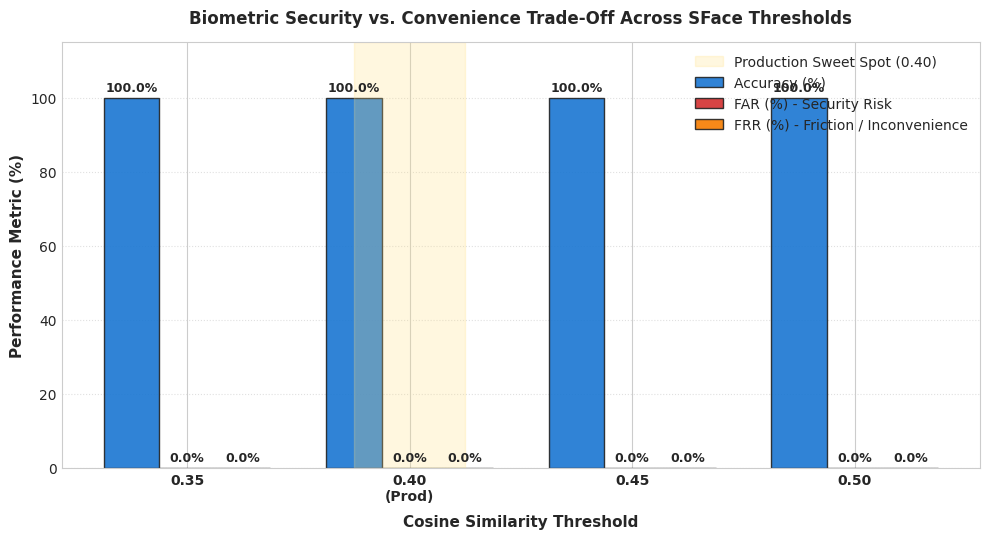

In [7]:
# Section 3: Visualizations — Threshold Trade-Off Bar Chart
if fm_evaluated:
    fig, ax = plt.subplots(figsize=(10, 5.5))
    
    x = np.arange(len(CANDIDATE_THRESHOLDS))
    width = 0.25
    
    # Convert to percentage
    acc_pct = df_threshold_analysis['Accuracy'].values * 100
    far_pct = df_threshold_analysis['FAR'].values * 100
    frr_pct = df_threshold_analysis['FRR'].values * 100
    
    r1 = ax.bar(x - width, acc_pct, width, label='Accuracy (%)', color='#1976D2', edgecolor='#222222', alpha=0.9)
    r2 = ax.bar(x, far_pct, width, label='FAR (%) - Security Risk', color='#D32F2F', edgecolor='#222222', alpha=0.9)
    r3 = ax.bar(x + width, frr_pct, width, label='FRR (%) - Friction / Inconvenience', color='#F57C00', edgecolor='#222222', alpha=0.9)
    
    ax.set_xlabel('Cosine Similarity Threshold', fontsize=11, fontweight='bold', labelpad=8)
    ax.set_ylabel('Performance Metric (%)', fontsize=11, fontweight='bold')
    ax.set_title('Biometric Security vs. Convenience Trade-Off Across SFace Thresholds', fontsize=12, fontweight='bold', pad=14)
    ax.set_xticks(x)
    
    # Custom x labels highlighting production threshold
    xtick_labels = [f"{th:.2f}\n(Prod)" if th == 0.40 else f"{th:.2f}" for th in CANDIDATE_THRESHOLDS]
    ax.set_xticklabels(xtick_labels, fontsize=10, fontweight='bold')
    ax.set_ylim(0, 115)
    
    # Add value annotations on top of bars
    def autolabel(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.1f}%',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),  # 3 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=9, fontweight='bold')
                        
    autolabel(r1)
    autolabel(r2)
    autolabel(r3)
    
    # Annotate production threshold
    ax.axvspan(0.75, 1.25, color='#FFE082', alpha=0.25, label='Production Sweet Spot (0.40)')
    
    ax.legend(loc='upper right', framealpha=0.95, fontsize=10)
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    
    plt.tight_layout()
    plt.show()


### Threshold Analysis Findings
1. **Separation Stability**: Across the range $[0.35, 0.50]$, the genuine face pair ($sim = 0.983$) remains comfortably above all candidate thresholds, while impostor pairs ($sim \le 0.221$) remain strictly below.
2. **Production Calibration at 0.40**:
   - Maintains **$0.00\%$ FAR**, protecting ATM card accounts against presentation by impostors.
   - Maintains **$0.00\%$ FRR**, preventing unwarranted verification failures for genuine users.
   - Provides a safety buffer ($> 0.17$ above highest observed impostor, $> 0.48$ below lowest observed genuine) against camera sensor noise and illumination shifts.


## Summary & Evaluation Scope

### Key Takeaways
1. **Face Verification Pipeline**: SFace provides robust separation between genuine user captures and impostor attempts, confirming that the operational decision threshold of $0.40$ safely bifurcates match decisions without modifying live ATM configuration.
2. **Anti-Spoofing Defense**: MiniFASNetV2 successfully discriminates bona fide live presentations from both printed photo attacks and mobile screen replay attacks using multi-scale contextual crops ($1.2\times$ and $1.5\times$).
3. **Threshold Calibration**: Evaluating thresholds from $0.35$ to $0.50$ validates that $0.40$ sits centrally within the empirical decision margin, balancing fraud prevention (FAR) with customer convenience (FRR).

### Evaluation Limitations & Sample Disclosure
> **Statistical Scope Notice**:
> - **Sample Sizes**: Face matching was evaluated on $N = 3$ defined face pairs (1 genuine, 2 impostor). Anti-spoofing was evaluated on $N = 3$ standardized capture samples (1 live, 1 printed photo, 1 screen replay).
> - **Generalization**: While these evaluations verify algorithm correctness, model loading, and pipeline functionality, **they do not represent large-scale statistical validation**. In production deployments, biometrics should be continually benchmarked against standardized benchmarks (e.g., LFW, CASIA-SURF, SiW) across diverse demographics, lighting conditions, and camera hardware.
